# **STEP 4, PART 1.4**

### **A selection of candidate ways to compare model and LAB (the shape of a likelihood), to give ideas and see which conclusions survice a change of variable**

The residuals of the grid searches (`abs`, `sq`, `rel`, with the Marasco+12 and Li+23 selections) are *not* likelihoods. They have no noise model, and their numbers and errors are not to be trusted. What can be trusted, if anything, is that an optimum and a trend exist and that they do not depend on the arbitrary choice of the variable. This notebook computes, for every model of the grids that already exist (`G1`, `M1`, `B1`), ten more per-voxel or per-block variables of the kind a Bayesian step could use, and compares what each says about:

- the optimum, and in particular $v_{\rm motion}$ and $\alpha_{\rm hv}$ (which we found to be ~flat), $hv$, and $\alpha_{\rm conds}$;
- the gain of the asymmetric stages over the symmetric one, in the noise units of that variable;
- the north/south trade (the halves of the residual);
- where each variable looks (which brightness and which latitude carries its weight).

No variable here is claimed to be right. They differ in what they believe about the discrepancy: its size relative to the model ($\sigma^2 = \sigma_0^2 + \epsilon^2 M^2$, with $\sigma_0 \approx 10$-$14$ mK and $\epsilon \approx 1$), its tails (Gaussian, Student-$t$, Huber, absolute), the transform that makes it homoscedastic (none, asinh, log) and its correlation (block sums over the correlation lengths).

## 0. Settings

In [1]:
import sys, re, json, pickle, time, os
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.optimize import nnls

sys.path.insert(1, "../EPG_Code/current_version_software")
sys.path.insert(1, "../EPG_Code/mw_addenda")
sys.path.insert(1, "../EPG_Code/fitting")

import grid_search as g
import grid_search_residuals as gr
import pack_grid as pg

# ---------------- where things are ----------------
WORK        = Path("./")                       # the step-4 folder: out_<STAGE>_*/, results_<STAGE>/, runs/
G1_DIR      = Path("../Grid_Search/results")   # the results folder of the symmetric grid search (G1)
G1_WORK     = G1_DIR.parent                    # its out_G1_*/, out_P1_*/, runs/
LAB_PATH    = "../Displays/lab.fit.gz"
PRODUCTS    = "../Convergence/lab_products.npz"
SFR_PROFILE = "../Tests/inputs/sfr_profile_marasco12.txt"
CONV        = Path("../Convergence/conv")
WORKERS     = 10
HERON_WORK  = "<redacted_for_privacy>"
PROBE_MIN, PROBE_MB, PROBE_N = 5.81, 1050.0, 40   # the time of the G1 job (an asymmetric model is x2 in gr.job_estimate) and the memory estimate of the asymmetric grid notebooks
HV0_MAX     = 120.0                            # the box of the grid searches
DIAG        = WORK / "diag_cache"              # everything this notebook writes (merged packs, fits, tables) goes here, never into the folders of the grid searches
DIAG.mkdir(exist_ok=True)

# ---------------- the stages ----------------
SYM  = dict(label="G1", stage="G1", check="P1", work=G1_WORK, res=G1_DIR)
ASYM = {"motion": dict(label="motion", stage="M1", check="PM1", work=WORK, res=WORK / "results_M1"),
        "cgm":    dict(label="cgm",    stage="C1", check="PC1", work=WORK, res=WORK / "results_C1"),
        "both":   dict(label="both",   stage="B1", check="PB1", work=WORK, res=WORK / "results_B1")}

# ---------------- the asymmetry of the runs (the same numbers as in the grid-search notebooks) ----------------
T_RATIO      = 1.12
GAMMA        = 5.0 / 3.0
RHO_RATIO    = T_RATIO ** (1.0 / (GAMMA - 1.0))
SOUTH_RATIOS = dict(south_vlag_ratio=T_RATIO, south_alpha_conds_ratio=RHO_RATIO, south_drag_ratio=RHO_RATIO)
V_MOTION_RANGE = (-60.0, 20.0)

# ---------------- the comparison with LAB: the same settings as the grid searches ----------------
B_CUT, L_CUT = 0, 0
V_DEV      = 35.0
REL_FLOOR  = 0.04

In [2]:
from mw_io import load_lab_products
from mw_display import Cube
from mw_cube import mirror_north_to_full_sky
from mw_mask import (disk_velocity_envelope, mask_disk_emission, mask_named_regions, flat_v_circ,
                     OUTER_ARM, GCP, EXTERNAL_GAL, MAGELLANIC)
from marasco_comp import *

def build_keep(cube_data, axes, bcut=None):
    l, b, v = axes
    bc = B_CUT if bcut is None else bcut
    vmin, vmax = disk_velocity_envelope(l, b, R0=8.275, v_circ_func=flat_v_circ(220.0))
    excl = mask_disk_emission(cube_data, v, vmin, vmax, v_dev_threshold=V_DEV, return_mask_only=True)
    excl |= mask_named_regions(l, b, v, [OUTER_ARM, GCP] + EXTERNAL_GAL + MAGELLANIC)
    excl |= (np.abs(b) < bc)[None, :, None]
    if L_CUT > 0: excl |= (np.abs((np.asarray(l, float) + 180.0) % 360.0 - 180.0) < L_CUT)[None, None, :]
    return ~excl

def to_full(cube_north, axes):
    full = mirror_north_to_full_sky(Cube(cube_north, *axes, "model"))
    return full.data, (full.l, full.b, full.v)

lab, l_lab, b_lab, v_lab, P = load_lab_products(PRODUCTS, lab_path=LAB_PATH, correction=False)
ax_lab = (l_lab, b_lab, v_lab); keep_lab = build_keep(lab, ax_lab)

SIGMA_NUM  = P.sigma_empty
T_M        = 0.04
K_L        = 2.0
RESIDUAL_SETS = {
    "base": dict(kind="soft"),
    "Mrsc": dict(kind="select", T=T_M, rel="max", blanks=False),
    "Li":   dict(kind="select", k=K_L, sigma=SIGMA_NUM, rel="max", blanks=True),
}
TAG = f"v{V_DEV:g}_L{L_CUT:g}_B{B_CUT:g}_f{REL_FLOOR:g}_T{T_M:g}_k{K_L:g}_s{SIGMA_NUM*1e3:.2f}"

cmp = MarascoComparison(lab, ax_lab, keep_lab, build_keep, to_full,
                        CompareConfig(beam_fwhm=8.0, sampling=4.0, dv=8.0),
                        rel_floor=REL_FLOOR, residual_sets=RESIDUAL_SETS)
cfg = cmp.cfg
KEYS = list(cmp.keys)
print(f"residual settings tag {TAG}\nComparison grid {len(cmp.v)} channels x {len(cmp.b)} b x {len(cmp.l)} l; keys: {KEYS}")

# the noise of one n = 40 run, per residual (convergence study)
PK_CONV = CONV / f"marasco_conv_{TAG}.pkl"
RES_CONV = pickle.load(open(PK_CONV, "rb")) if PK_CONV.exists() else {}
RES_CONV = {n: r for n, r in RES_CONV.items() if r.get("keys") == KEYS}
GN = {}
for nm in RES_CONV:
    m = re.match(r"N(\d+)_s(\d+)$", nm)
    if m: GN.setdefault(f"N{m[1]}", []).append(nm)
if RES_CONV and len(GN.get("N40", [])) >= 3:
    NOISE = gr.noise_table_from_conv(RES_CONV, GN, KEYS)
else:
    NOISE = {k: dict(gr.NOISE_FALLBACK[k]) for k in KEYS}
S40 = {k: float(gr._interp_noise(NOISE[k], 40)) for k in KEYS}      # relative noise of one n = 40 run

print("Noise of one n = 40 run [%]:", {k: round(100 * S40[k], 2) for k in KEYS})

> Seam columns differ by at most 4.5024986 K
LAB products of 2026-10-22: sigma = 3.123 mK (empty channels), 3.236 mK (null test)
Correction file on same directory: none
Note: correction=False, the stored correction is NOT applied; the stored sigma belongs to the corrected cube.
residual settings tag v35_L0_B0_f0.04_T0.04_k2_s3.12
Comparison grid 62 channels x 41 b x 90 l; keys: ['abs', 'sq', 'rel', 'abs_Mrsc', 'sq_Mrsc', 'rel_Mrsc', 'abs_Li', 'sq_Li', 'rel_Li']
Noise of one n = 40 run [%]: {'abs': 1.26, 'sq': 3.95, 'rel': 0.94, 'abs_Mrsc': 1.35, 'sq_Mrsc': 3.97, 'rel_Mrsc': 1.38, 'abs_Li': 1.31, 'sq_Li': 3.95, 'rel_Li': 1.05}


## 1. Load the stages

For every stage (`G1`, `M1`, `C1`, `B1`) the residual cache `grid_resid_<TAG>.pkl` of its `results` folder is read. Models that the cache does not have yet (the check stages, if their notebook was not run after the job) are evaluated from the pack. The run files give the parameters and the group (stage) of every model.

In [3]:
def load_set(S):
    """ Residuals and runs of one stage and its check stage: S = SYM or one of ASYM. """
    runs = {}
    for f in sorted((S["work"] / "runs").glob("grid4d_*.json")): runs.update(g.load_runs(f))
    runs = {n: r for n, r in runs.items() if r["group"] in (S["stage"], S["check"])}
    cache = S["res"] / f"grid_resid_{TAG}.pkl"                 # read only
    res = {}
    if cache.exists():
        res = {n: r for n, r in pickle.load(open(cache, "rb")).items() if r.get("keys") == KEYS and n in runs}

    missing = [n for n in runs if n not in res]
    if missing:
        pack = get_pack(S["label"], S)
        if pack is None:
            print(f"> {S['label']}: {len(missing)} models are not in the cache and there is no pack: they are left out.")
        else:
            todo = [n for n in missing if n in pack.names]
            new = gr.evaluate_pack(pack, cmp, names=todo, cache=DIAG / f"resid_{S['label']}_{TAG}.pkl", workers=WORKERS)
            res.update(new)
    return res, runs

PACKS = {}
def get_pack(label, S=None):
    """
    The pack of a stage and its check stage (merged into the diagnostics folder, 
    never into the folders of the grid searches).
    """
    if label not in PACKS:
        S = S or STG[label]
        files = sorted(S["work"].glob(f"out_{S['stage']}_*/pack.fits")) + \
                sorted(S["work"].glob(f"out_{S['check']}_*/pack.fits"))
        
        PACKS[label] = gr.open_packs(files, DIAG / f"pack_{label}.fits") if files else None

    return PACKS[label]

STG = {}    # the stages, by label: STG["G1"], STG["motion"], STG["cgm"], STG["both"].
for S in [SYM] + list(ASYM.values()):
    res, runs = load_set(S)
    STG[S["label"]] = dict(S, RES=res, RUNS=runs)
    n_stage = sum(1 for n in res if runs[n]["group"] == S["stage"])
    n_chk = sum(1 for n in res if runs[n]["group"] == S["check"])
    print(f"{S['label']:7s} {S['stage']}: {n_stage:4d} models of the grid, {S['check']}: {n_chk:3d} replicates")

def rep_groups(res, stage):
    """ {place: [model names]} of the replicates of a check stage ('<stage>_<place>_s<k>'). """
    pat = re.compile(rf"^{re.escape(stage)}_(.+)_s(\d+)$"); out = {}
    for n in res:
        m = pat.match(n)
        if m: out.setdefault(m[1], []).append(n)
    return out

for lab_, T in STG.items():
    T["REP"] = rep_groups(T["RES"], T["check"])
    print(f"{lab_:7s} places of {T['check']}: {sorted(T['REP'])}")

# ---- the best model of a stage, and its cubes on the comparison grid (used in sections 4 and 6)
STRUCT_KEY = "abs_Li"

def best_model(label, key=STRUCT_KEY):
    """ 
    The replicate of median R at the stage's own optimum of `key` (representative, not a lucky draw).
    Without the check stage, it is the best grid model.
    """
    T = STG[label]; reps = T["REP"].get(f"opt_{key}", [])
    if reps:
        order = sorted(reps, key=lambda n: T["RES"][n]["R_" + key]); return order[len(order) // 2]
    names = [n for n in T["RES"] if T["RUNS"][n]["group"] == T["stage"]]

    return min(names, key=lambda n: T["RES"][n]["R_" + key])

def field_cubes(label, name):
    """ Data, scaled model and sigma on the comparison cube (NaN where invalid), and the evaluation (with its vectors). """
    mod = get_pack(label).cmp_cube(name)
    ev = cmp.evaluate(mod, keep_vectors=True); vec = ev["vec"]
    shape = cmp.lab_cmp.data.shape
    D = np.full(shape, np.nan); M = np.full(shape, np.nan); W = np.zeros(shape)
    D[vec["valid"]] = vec["d"]; M[vec["valid"]] = vec["m"]; W[vec["valid"]] = vec["w"]
    S = np.full(shape, float(SIGMA_NUM))
    
    return D, M, W, S, ev

G1      G1:  512 models of the grid, P1:  80 replicates
motion  M1:  512 models of the grid, PM1:  80 replicates
cgm     C1:  512 models of the grid, PC1:  80 replicates
both    B1:  512 models of the grid, PB1:  80 replicates
G1      places of P1: ['marasco', 'opt_abs', 'opt_abs_Li', 'opt_abs_Mrsc', 'opt_rel', 'opt_rel_Li', 'opt_rel_Mrsc', 'opt_sq', 'opt_sq_Li', 'opt_sq_Mrsc']
motion  places of PM1: ['marasco', 'opt_abs', 'opt_abs_Li', 'opt_abs_Mrsc', 'opt_rel', 'opt_rel_Li', 'opt_rel_Mrsc', 'opt_sq', 'opt_sq_Li', 'opt_sq_Mrsc']
cgm     places of PC1: ['marasco', 'opt_abs', 'opt_abs_Li', 'opt_abs_Mrsc', 'opt_rel', 'opt_rel_Li', 'opt_rel_Mrsc', 'opt_sq', 'opt_sq_Li', 'opt_sq_Mrsc']
both    places of PB1: ['marasco', 'opt_abs', 'opt_abs_Li', 'opt_abs_Mrsc', 'opt_rel', 'opt_rel_Li', 'opt_rel_Mrsc', 'opt_sq', 'opt_sq_Li', 'opt_sq_Mrsc']


## 2. The variables

Per voxel, with $D$ = LAB, $M$ = the scaled model (the flux scale of the grid searches: one for the whole sky), $w = \cos b$, and $s^2(M) = \sigma_0^2 + \epsilon^2 M_+^2$ (the *scatter law*: the discrepancy grows with the model flux):

| key | per-voxel term | what it believes |
|---|---|---|
| `chi_sc` | $w (D - M)^2 / s^2$ | Gaussian, model-dependent width; no normalization term (a weighting) |
| `nll_sc` | $w [(D - M)^2 / s^2 + \ln (s^2 / \sigma_0^2)]$ | the same with the normalization of the Gaussian, i.e. a proper $-2 \ln L$ for independent voxels (up to a constant) |
| `t3_sc` | $w [(\nu + 1) \ln (1 + (D - M)^2 / (\nu s^2)) + \ln (s^2 / \sigma_0^2)]$, $\nu = 3$ | heavy tails: the 20-70 % voxels count less |
| `huber_sc` | $w\, \rho_k(\|D - M\| / s)$, $\rho_k(x) = x^2/2$ for $x < k$, $kx - k^2/2$ above, $k = 1.5$ | Gaussian core, Laplace tails |
| `abs_sc` | $w \|D - M\| / s$ | a weighted L1 |
| `asinh2` | $w [\operatorname{asinh}(D / \sigma_0) - \operatorname{asinh}(M / \sigma_0)]^2$ | the discrepancy is multiplicative at high flux and additive near zero: asinh makes it homoscedastic (linear below $\sigma_0$, logarithmic above) |
| `asinh1` | the same with $\|\cdot\|$ | |
| `lnfl` | $w \|\ln [(D_+ + \sigma_0) / (M_+ + \sigma_0)]\|$ | a log ratio with a floor |
| `blk_abs` | $\sum_{\rm blocks} \|\sum w D - \sum w M\|$ | only the *block-integrated* residual counts (blocks of $4 \times 4 \times 4$ cells = 16° x 16° x 32 km/s, the correlation lengths of section 6c): coherent offsets add, voxel scatter averages out |
| `blk_chi` | $\sum_{\rm blocks} (\sum w D - \sum w M)^2 / (\sigma_0^2 \sum w^2 + \epsilon^2 (\sum w M)^2)$ | the same with a Gaussian block error |

The reference rows (`abs`, `abs_Li`, `sq_Li`, `rel_Li`) are read from the grid caches. The noise of every variable (the relative scatter of one $n = 40$ run) is measured from the replicates of the check stages: there is no convergence study for the new ones.

In [4]:
SIG0, EPS = 0.012, 1.0  # K: sigma_0 = 10-14 mK and eps ~ 1.0 (rms) (from the previous notebook)/
NU, HUBER_K = 3.0, 1.5
BLK = (4, 4, 4)         # block in (v, b, l) cells of the comparison grid (8 km/s, 4 deg, 4 deg): 32 km/s x 16 deg x 16 deg

def s_of(M): return np.sqrt(SIG0 ** 2 + (EPS * np.clip(M, 0.0, None)) ** 2)
def _huber(x, k=HUBER_K): return np.where(x < k, 0.5 * x ** 2, k * x - 0.5 * k ** 2)

VARS = {
    "chi_sc":   lambda D, M, w: w * (D - M) ** 2 / s_of(M) ** 2,
    "nll_sc":   lambda D, M, w: w * ((D - M) ** 2 / s_of(M) ** 2 + np.log(s_of(M) ** 2 / SIG0 ** 2)),
    "t3_sc":    lambda D, M, w: w * ((NU + 1.0) * np.log1p((D - M) ** 2 / (NU * s_of(M) ** 2)
                                                           ) + np.log(s_of(M) ** 2 / SIG0 ** 2)),
    "huber_sc": lambda D, M, w: w * _huber(np.abs(D - M) / s_of(M)),
    "abs_sc":   lambda D, M, w: w * np.abs(D - M) / s_of(M),
    "asinh2":   lambda D, M, w: w * (np.arcsinh(D / SIG0) - np.arcsinh(M / SIG0)) ** 2,
    "asinh1":   lambda D, M, w: w * np.abs(np.arcsinh(D / SIG0) - np.arcsinh(M / SIG0)),
    "lnfl":     lambda D, M, w: w * np.abs(np.log((np.clip(D, 0.0, None) + SIG0) / (np.clip(M, 0.0, None) + SIG0))),
}
BLOCK_KEYS = ["blk_abs", "blk_chi"]
NEW_KEYS = list(VARS) + BLOCK_KEYS
OLD_KEYS = ["abs", "abs_Li", "sq_Li", "rel_Li"]
ALL_KEYS = OLD_KEYS + NEW_KEYS
LIKTAG = f"{TAG}_s{SIG0 * 1e3:.1f}_e{EPS:g}_nu{NU:g}_h{HUBER_K:g}_b{BLK[0]}{BLK[1]}{BLK[2]}"

class LikComparison(MarascoComparison):
    """ 
    The comparison of the grid searches with other per-voxel terms: 
        keys = the variables of VARS (everything else of the evaluation is unchanged: 
        flux scale, masks, N/S halves, jackknife). 
    """
    def __init__(self, *args, vars_, **kw):
        super().__init__(*args, **kw)
        self.vars_ = vars_; self.keys = list(vars_); self.sets = {n: dict(kind="var") for n in vars_}
    def _terms(self, data, model, weight):
        return [f(data, model, weight) for f in self.vars_.values()]

cmpL = LikComparison(lab, ax_lab, keep_lab, build_keep, to_full, 
                     CompareConfig(beam_fwhm=8.0, sampling=4.0, dv=8.0), rel_floor=REL_FLOOR, vars_=VARS)

def block_terms(vec):
    """ 
    The block-summed variables of one evaluation (needs the voxel vectors): 
    totals and the north / south halves (a block never mixes the hemispheres). 
    """
    iv, ib, il = (a.astype(np.int64) for a in np.nonzero(vec["valid"]))
    isN = (np.asarray(cmpL.b, float)[ib] > 0).astype(np.int64)
    bid = ((((iv // BLK[0]) * 1000 + (ib // BLK[1])) * 1000 + (il // BLK[2])) * 2 + isN)
    u, inv = np.unique(bid, return_inverse=True)
    w, d, m = vec["w"], vec["d"], vec["m"]

    SD, SM, SW2 = np.bincount(inv, w * d), np.bincount(inv, w * m), np.bincount(inv, w * w)
    north = (u % 2 == 1)
    t_abs = np.abs(SD - SM)
    t_chi = (SD - SM) ** 2 / (SIG0 ** 2 * SW2 + EPS ** 2 * np.clip(SM, 0.0, None) ** 2)
    out = {}

    for k, t in (("blk_abs", t_abs), ("blk_chi", t_chi)):
        out["R_" + k] = float(t.sum())
        out["R_" + k + "_N"] = float(t[north].sum())
        out["R_" + k + "_S"] = float(t[~north].sum())
    return out

def lik_fn(cmp_, mod):
    ev = cmp_.evaluate(mod, keep_vectors=True)
    vec = ev.pop("vec")
    ev.update(block_terms(vec))
    return ev

# A check: the variables of one model, per voxel, are non-negative and finite.
_F = field_cubes("G1", best_model("G1")); _v = _F[4]["vec"]
for k, f in VARS.items():
    t = f(_v["d"], _v["m"], _v["w"])
    assert np.isfinite(t).all() and (t >= -1e-12).all(), f"{k}: negative or non-finite terms."
print(f"The {len(VARS)} per-voxel variables are finite and non-negative on the best G1 model; block keys:", BLOCK_KEYS)

The 8 per-voxel variables are finite and non-negative on the best G1 model; block keys: ['blk_abs', 'blk_chi']


## 3. Evaluate every model of the three stages

Every model of the merged pack (grid + check stage) of `G1`, `M1`, and `B1` is evaluated with the new variables (cache in the diagnostics folder, named after the settings above, so changing $\sigma_0$ or $\epsilon$ recomputes).

In [5]:
LABELS = ["G1", "motion", "both"]
LIKRES = {}
for lab_ in LABELS:
    LIKRES[lab_] = gr.evaluate_pack(get_pack(lab_), cmpL, cache=DIAG / f"lik_{lab_}_{LIKTAG}.pkl", workers=WORKERS, fn=lik_fn)
def _rvals(r): return {k: v for k, v in r.items() if k.startswith("R_") and k != "R_loo"}
ALLRES = {lab_: {n: {**_rvals(STG[lab_]["RES"][n]), **_rvals(LIKRES[lab_][n]), "keys": ALL_KEYS} for n in LIKRES[lab_] if n in STG[lab_]["RES"]} for lab_ in LABELS}
GRID = {lab_: {n: r for n, r in ALLRES[lab_].items() if STG[lab_]["RUNS"][n]["group"] == STG[lab_]["stage"]} for lab_ in LABELS}
print({lab_: (len(GRID[lab_]), len(ALLRES[lab_]) - len(GRID[lab_])) for lab_ in LABELS}, " (grid models, replicates)")

0 new evaluations in 0 s; 592 models evaluated
0 new evaluations in 0 s; 592 models evaluated
0 new evaluations in 0 s; 592 models evaluated
{'G1': (512, 80), 'motion': (512, 80), 'both': (512, 80)}  (grid models, replicates)


**The noise of each variable (relative scatter of one $n = 40$ run) from the replicates.** 

For every place with at least six seeds, the standard deviation of $\ln R$ is the noise. Three numbers are shown. 

* The *pooled* value (variance pooled over places) is dominated by the few heavy-tailed runs (about 1 % of the models are 20-70 % off their same seed) and is not used. 

* The *robust* value is the median of the place standard deviations, divided by the factor by which a median of sample standard deviations of $n$ seeds falls below the true one (0.95 for 8 seeds). It is the scatter of an ordinary run, and it is what the fits and the $u$ columns use for the new variables. 

* For the old keys, the convergence study stays the reference (same runs and tools as in the earlier notebooks) and the robust value is printed as a check of the method.

In [6]:
from scipy.stats import chi2 as _chi2
def noise_from_replicates(key):
    """ 
    Pooled sd of ln R over the places with >= 6 seeds, 
    the robust one = median of the place sds corrected for the bias of a median, the list of place sds.
    """
    num = den = 0.0; sds = []; cs = []
    for lab_ in LABELS:
        for _, names in STG[lab_]["REP"].items():
            vals = np.array([ALLRES[lab_][n]["R_" + key] for n in names if n in ALLRES[lab_]])
            
            if len(vals) >= 6:
                sd = np.std(np.log(vals), ddof=1)
                num += (len(vals) - 1) * sd ** 2
                den += len(vals) - 1
                sds.append(sd)
                cs.append(np.sqrt(_chi2.median(len(vals) - 1) / (len(vals) - 1)))
    pooled = np.sqrt(num / den) if den else np.nan
    robust = np.median(sds) / np.median(cs) if sds else np.nan
    return pooled, robust, sds

NOISE_ALL = dict(NOISE); S40V = {}
print(f"{'variable':10s} {'pooled [%]':>11s} {'robust [%]':>11s} {'convergence [%]':>16s} "
      f"{'places':>7s} {'place sds 25/50/75 % [%]':>26s} {'places > 3 x robust':>20s}")
for k in ALL_KEYS:
    pooled, rob, sds = noise_from_replicates(k)
    ref = S40.get(k, np.nan)

    # The unit u of a variable: the convergence study where it has one, else the robust value.
    if k in NEW_KEYS and np.isfinite(rob):
        S40V[k] = ref if np.isfinite(ref) else rob

    NOISE_ALL[k] = {40: float(rob)}

    q = np.percentile(sds, [25, 50, 75]) * 100 if sds else [np.nan] * 3
    print(f"{k:10s} {100 * pooled:11.2f} {100 * rob:11.2f} {100 * ref:16.2f} {len(sds):7d} "
          f"{'%.2f / %.2f / %.2f' % tuple(q):>26s} {int(np.sum(np.array(sds) > 3 * rob)):20d}")
    
print("\nu = the noise of one n = 40 run of that variable: the convergence study where it exists, "
      "\nelse the robust value (the 'robust' column).")

variable    pooled [%]  robust [%]  convergence [%]  places   place sds 25/50/75 % [%]  places > 3 x robust
abs               4.93        0.87             1.26      30         0.58 / 0.83 / 1.09                    3
abs_Li            4.99        0.88             1.31      30         0.59 / 0.84 / 1.14                    3
sq_Li            58.52        2.23             3.95      30         1.55 / 2.12 / 3.16                    3
rel_Li            2.26        0.59             1.05      30         0.44 / 0.56 / 0.76                    2
chi_sc           29.41        4.24              nan      30         2.94 / 4.03 / 5.09                    2
nll_sc           28.03        2.79              nan      30         1.95 / 2.66 / 3.67                    2
t3_sc             3.68        0.51              nan      30         0.40 / 0.48 / 0.83                    3
huber_sc         13.76        2.14              nan      30         1.62 / 2.03 / 2.43                    2
abs_sc            9.57      

## 4. The optimum of every variable, in every stage

For each variable and stage a surface (the GP of the grid searches, $y = -\ln R / s$ over the parameters: `hv0`, `alpha_conds`, `alpha_hv`, `f_ion` and, in `M1` and `B1`, `v_motion`) and its optimum with the GP uncertainty (a surface uncertainty, not a likelihood interval).

In [7]:
RUN_FITS = True
FIT_KEYS = ALL_KEYS # Here, we can trim to fit fewer if needed.
PN = ("hv0", "alpha_conds", "alpha_hv", "f_ion", "v_motion")
PNAMES = {"G1": PN[:4], "motion": PN, "both": PN}

box = g.Box(names=PN, lo=(50.0, 0.0, 0.0, 0.0, V_MOTION_RANGE[0]), hi=(HV0_MAX, 10.0, 0.5, 1.0, V_MOTION_RANGE[1]))
box4 = g.Box(names=PN[:4], lo=box.lo[:4], hi=box.hi[:4])
sfr = np.loadtxt(SFR_PROFILE) if Path(SFR_PROFILE).exists() else None
_sf = (lambda R: np.interp(np.asarray(R, float), sfr[:, 0], sfr[:, 1])) if sfr is not None else None
feat, feat4 = g.Features(box, sfrd=_sf), g.Features(box4, sfrd=_sf)
BOXF = {"G1": (box4, feat4), "motion": (box, feat), "both": (box, feat)}

FIT = {}
if RUN_FITS:
    for lab_ in LABELS:
        bx, ft = BOXF[lab_]; runs_g = {n: STG[lab_]["RUNS"][n] for n in GRID[lab_]}
        for k in FIT_KEYS:
            if k not in NOISE_ALL or "R_" + k not in next(iter(GRID[lab_].values())): 
                continue
            o = gr.optima_cached(DIAG / f"lik_fit_{lab_}_{k}_{LIKTAG}.pkl", 
                                 GRID[lab_], runs_g, [k], NOISE_ALL, bx, ft, n_draws=200, n_restarts=4, jackknife=False)
            if k in o: 
                FIT[(lab_, k)] = o[k]

print(len(FIT), "fits are ready.")

def opt_val(lab_, k, name):
    # (median of the draws, GP sd) of one parameter at the optimum of variable k in stage lab_.
    # (nan, nan) if the stage does not have it.
    o = FIT.get((lab_, k))
    if o is None or (name != "hv_pivot" and name not in PNAMES[lab_]): 
        return np.nan, np.nan
    
    est = o["est"]
    if name == "hv_pivot": 
        return est["hv_pivot"]["p50"], gr._sd_gp(est, None)
    
    j = PNAMES[lab_].index(name)
    return est["p50"][j], gr._sd_gp(est, j)

def cell(lab_, k, name):
    m, s = opt_val(lab_, k, name)
    return "-" if not np.isfinite(m) else f"{m:7.2f} ±{s:5.2f}"

42 fits are ready.


In [8]:
COLS5 = ("hv_pivot", "alpha_conds", "alpha_hv", "f_ion", "v_motion")
for lab_ in ("motion", "both"):
    print(f"\n{lab_.upper()}: optimum (median of the draws +- GP sd) of every variable\n"
          "Last column: mean of the 10 best grid models relative to G1's, in % and in noise units u of one run")
    print(f"{'variable':10s} " + " ".join(f"{c:>15s}" for c in COLS5) + f"   {'gain over G1':>22s}")
    for k in ALL_KEYS:
        if (lab_, k) not in FIT: continue
        b = np.sort([r["R_" + k] for r in GRID[lab_].values()])[:10].mean()
        a = np.sort([r["R_" + k] for r in GRID["G1"].values()])[:10].mean()
        err = f"{np.log(b / a) / S40V[k]:+5.1f}" if k in S40V else "    -"
        print(f"{k:10s} " + " ".join(f"{cell(lab_, k, n):>15s}" for n in COLS5) + f"   {100 * (b / a - 1):+7.2f} % ({err} u)")
        
print("\nG1 (symmetric)")
print(f"{'variable':10s} " + " ".join(f"{c:>15s}" for c in COLS5[:4]))
for k in ALL_KEYS:
    if ("G1", k) in FIT: print(f"{k:10s} " + " ".join(f"{cell('G1', k, n):>15s}" for n in COLS5[:4]))
print("\n(The best-10 means are biased low by the selection of lucky draws by about the same amount in G1 and in M1/B1,\n"
      "so the difference is meaningful, the sign of a small one is not a proof.)")


MOTION: optimum (median of the draws +- GP sd) of every variable
Last column: mean of the 10 best grid models relative to G1's, in % and in noise units u of one run
variable          hv_pivot     alpha_conds        alpha_hv           f_ion        v_motion             gain over G1
abs          103.34 ±18.59     4.66 ± 2.31     0.42 ± 0.18     0.00 ± 0.03   -39.83 ± 9.93     -0.93 % (    - u)
abs_Li        73.80 ± 8.13     9.02 ± 1.13     0.00 ± 0.04     0.00 ± 0.01   -34.07 ± 9.85     -1.72 % (    - u)
sq_Li         95.93 ±21.01     4.16 ± 2.85     0.21 ± 0.14     0.42 ± 0.47   -34.44 ±25.21     -3.79 % (    - u)
rel_Li       122.75 ± 5.24     9.07 ± 0.68     0.38 ± 0.03     0.00 ± 0.00   -16.95 ±10.26     -0.38 % (    - u)
chi_sc       111.58 ± 6.66     6.61 ± 0.79     0.50 ± 0.05     1.00 ± 0.10   -14.71 ± 6.29     +1.65 % ( +0.4 u)
nll_sc        82.95 ± 9.76     6.95 ± 0.34     0.50 ± 0.00     1.00 ± 0.00   -26.62 ± 2.59     -0.77 % ( -0.3 u)
t3_sc         71.29 ± 4.79     5.96 ± 1.

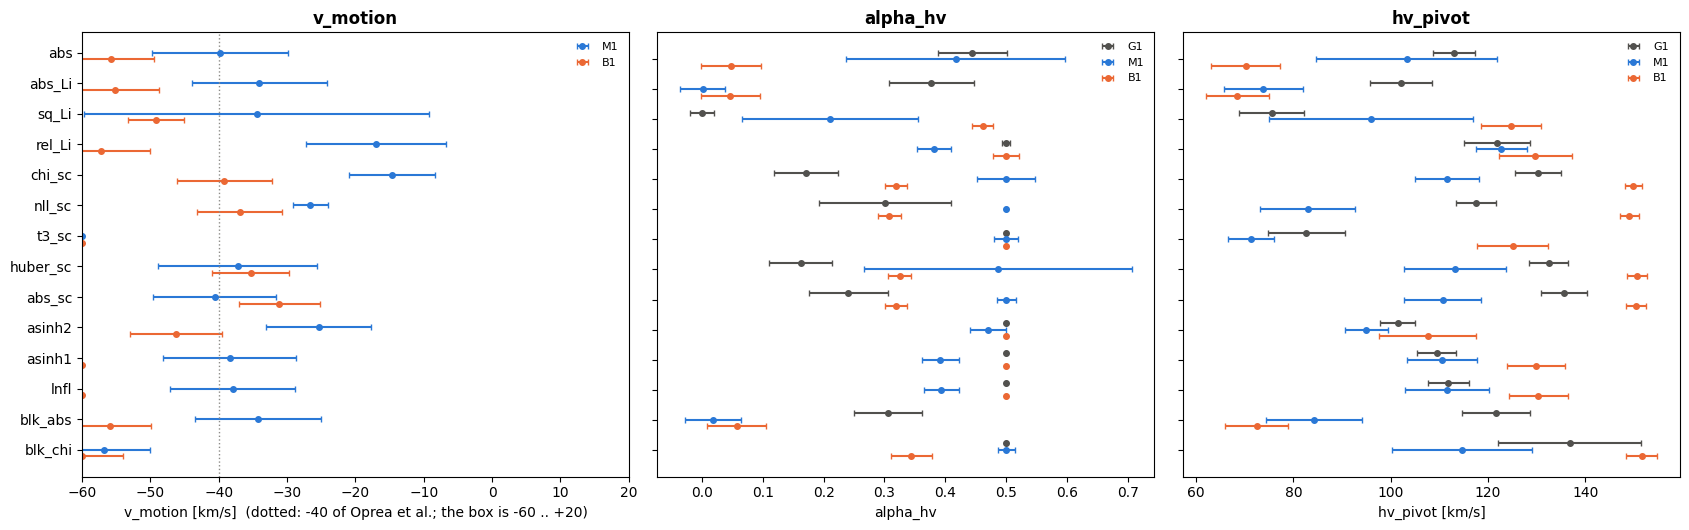

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(17, 5.4), gridspec_kw=dict(width_ratios=[1.1, 1, 1]))
ks = [k for k in ALL_KEYS if ("motion", k) in FIT or ("both", k) in FIT]
ypos = np.arange(len(ks))
STY = {"G1": (-0.22, "#52514e", "G1"), "motion": (0.0, "#2a78d6", "M1"), "both": (0.22, "#eb6834", "B1")}

for ax, nm, labs in ((axs[0], "v_motion", ("motion", "both")), 
                     (axs[1], "alpha_hv", ("G1", "motion", "both")), 
                     (axs[2], "hv_pivot", ("G1", "motion", "both"))):
    for lab_ in labs:
        off, col, nice = STY[lab_]
        mm = np.array([opt_val(lab_, k, nm) for k in ks])
        ax.errorbar(mm[:, 0], ypos + off, xerr=mm[:, 1], fmt="o", ms=4, color=col, capsize=2, label=nice)
    ax.set_yticks(ypos)
    ax.set_yticklabels(ks if nm == "v_motion" else [])
    ax.invert_yaxis()
    ax.legend(frameon=False, fontsize=8)
    ax.set_xlabel(nm + (" [km/s]" if nm != "alpha_hv" else ""))
    ax.set_title(nm, weight="bold")

axs[0].axvline(-40, color="#8d8c88", ls=":", lw=1)
axs[0].set_xlim(*V_MOTION_RANGE)
axs[0].set_xlabel("v_motion [km/s]  (dotted: -40 of Oprea et al.; the box is -60 .. +20)")

plt.tight_layout()
plt.show()

**Profiles.** 

We look at the profile of each surface along $\alpha_{\rm hv}$, $\alpha_{\rm conds}$, $hv$ at the pivot, and (`M1`) $v_{\rm motion}$. How much $\ln R$ rises when the parameter is moved with the others re-optimised (the maximum of the surface in bins over a Sobol cloud; a profile of the *residual*, not of a likelihood)? 

The vertical axis is in noise units $u$ of one $n = 40$ run of that variable, so curves of different variables are comparable: a profile that never rises above ~2 $u$ is a parameter that variable cannot see. Some are highlighted.

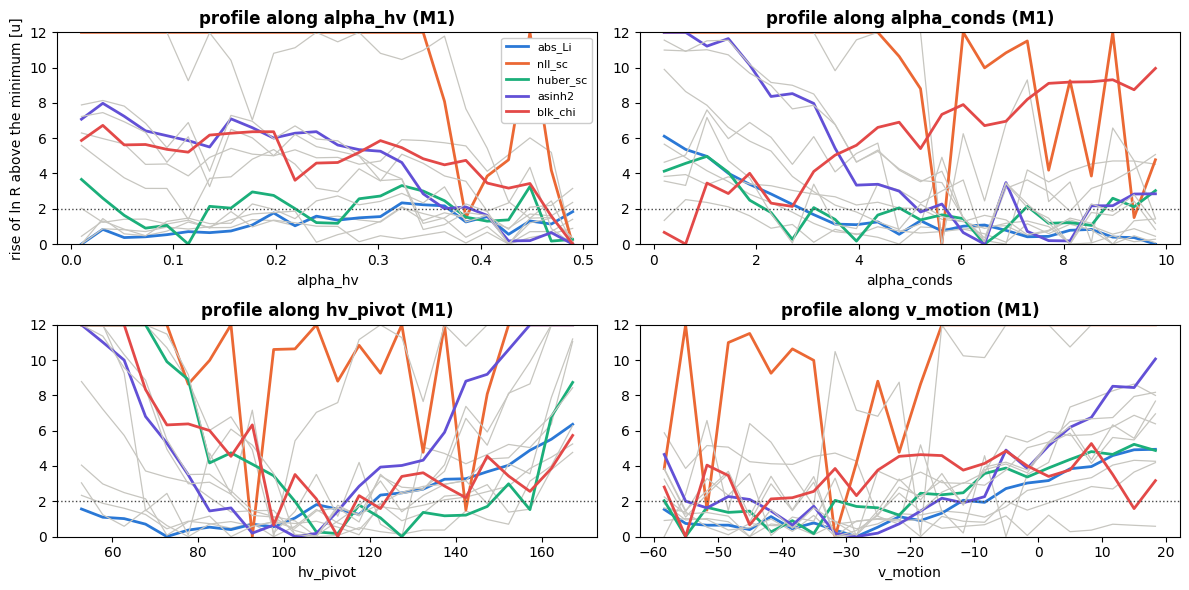

In [10]:
HILITE = ["abs_Li", "nll_sc", "huber_sc", "asinh2", "blk_chi"]
COLS = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#e34948"]
PRO_LAB = "motion"

fig, axs = plt.subplots(2, 2, figsize=(12, 6))
for ax, nm in zip(axs.flat, ("alpha_hv", "alpha_conds", "hv_pivot", "v_motion")):
    for k in [k for k in ALL_KEYS if (PRO_LAB, k) in FIT]:
        o = FIT[(PRO_LAB, k)]
        pc = g.profile_curves(o["gp"], feat, box, m=8000, n_bins=24)[nm]
        rise = np.clip(-pc[1], 0, 12) # y = -ln R / s_ref is already in noise units of one n = 40 run.
        if k in HILITE: ax.plot(pc[0], rise, "-", color=COLS[HILITE.index(k)], lw=2, label=k)
        else: ax.plot(pc[0], rise, "-", color="#c7c6c0", lw=0.9)

    ax.set(xlabel=nm, ylabel="rise of ln R above the minimum [u]" if nm == "alpha_hv" else "", ylim=(0, 12))
    ax.set_title(f"profile along {nm} (M1)", weight="bold")
    ax.axhline(2, color="#464646", ls=":", lw=1)
axs[0, 0].legend(framealpha=1, fontsize=8)

plt.tight_layout()
plt.show()

## 5. The north-south trade, variable by variable

The hemisphere halves of every variable (`R_<key>_N`, `R_<key>_S`, with the one flux scale of the whole sky) at the 10 best grid models of each stage, `M1` and `B1` against `G1` (mean of the 10 best of each, change in % of the variable's total of G1).

The question we are after is: does the south gain and the north pay for every variable? Then, the hemisphere fits of $v_{\rm motion}$ (north from the pooled `M1 + B1` north halves, south from `M1`) for a few variables: does the north's indifference to the tail wind and the south's wish for a head wind depend on the variable? 

*(It is important to note that this is only confirm that our pipeline is not misfitting anything. In reality, the disl moves as a whole. A different optimum per hemisphere is a statement about what each half of the model-LAB difference wants, not a physical result.)*

In [11]:
print(f"{'variable':10s} | {'M1: north':>10s} {'south':>9s} {'total':>9s} | {'B1: north':>10s} {'south':>9s} {'total':>9s}  (change at the 10 best models, in % of G1's total)")
for k in ALL_KEYS:
    if "R_" + k + "_N" not in next(iter(GRID["G1"].values())): continue
    bestG = sorted(GRID["G1"].values(), key=lambda r: r["R_" + k])[:10]; tot_g = np.mean([r["R_" + k] for r in bestG]); row = f"{k:10s} | "
    for lab_ in ("motion", "both"):
        best = sorted(GRID[lab_].values(), key=lambda r: r["R_" + k])[:10]
        dN = np.mean([r["R_" + k + "_N"] for r in best]) - np.mean([r["R_" + k + "_N"] for r in bestG])
        dS = np.mean([r["R_" + k + "_S"] for r in best]) - np.mean([r["R_" + k + "_S"] for r in bestG])
        row += f"{100 * dN / tot_g:+9.2f}% {100 * dS / tot_g:+8.2f}% {100 * (dN + dS) / tot_g:+8.2f}% | "
    print(row)

variable   |  M1: north     south     total |  B1: north     south     total  (change at the 10 best models, in % of G1's total)
abs        |     +7.11%    -8.04%    -0.93% |     +7.57%    -8.82%    -1.25% | 
abs_Li     |     +7.60%    -9.32%    -1.72% |     +8.14%   -10.39%    -2.26% | 
sq_Li      |     +1.21%    -5.00%    -3.79% |     +0.20%    -4.23%    -4.02% | 
rel_Li     |     +0.61%    -0.99%    -0.38% |     +0.38%    -0.76%    -0.38% | 
chi_sc     |     -8.02%    +9.67%    +1.65% |    -10.39%    +8.79%    -1.60% | 
nll_sc     |     -3.04%    +2.26%    -0.77% |     -4.59%    +1.52%    -3.07% | 
t3_sc      |     +1.84%    -4.37%    -2.53% |     +1.34%    -4.51%    -3.16% | 
huber_sc   |     -2.89%    +1.90%    -0.99% |     -3.77%    +2.56%    -1.21% | 
abs_sc     |     -0.98%    +0.66%    -0.31% |     -0.96%    +0.63%    -0.32% | 
asinh2     |     +3.96%    -6.83%    -2.88% |     +5.21%    -8.03%    -2.82% | 
asinh1     |     +1.37%    -3.21%    -1.84% |     +0.49%    -2.34%    -

In [12]:
RUN_HEMI_FITS = True
HEMI_KEYS = ["abs_Li", "nll_sc", "asinh2", "t3_sc", "blk_chi"]
HFIT = {}
if RUN_HEMI_FITS:
    for k in ALL_KEYS:
        if k not in NOISE_ALL: continue
        for hname, parts in (("north", ("motion", "both")), ("south", ("motion",))):
            h = hname[0].upper()
            res, runs = {}, {}
            for lab_ in parts:
                for n, r in GRID[lab_].items(): 
                    res[n] = {"keys": [k], "R_" + k: r["R_" + k + "_" + h]}
                    runs[n] = STG[lab_]["RUNS"][n]
            o = gr.optima_cached(DIAG / f"lik_hfit_{hname}_{k}_{LIKTAG}.pkl", res, runs, [k], 
                                 NOISE_ALL, box, feat, n_draws=200, n_restarts=4, jackknife=False)
            if k in o:
                HFIT[(hname, k)] = o[k]

    def hc(o, j): return f"{o['est']['p50'][j]:7.1f} ±{gr._sd_gp(o['est'], j):5.1f}"

    print(f"{'variable':10s} {'north v_motion':>18s} {'south v_motion':>18s} {'whole sky (M1)':>18s} | "
          f"{'north alpha_hv':>16s} {'south alpha_hv':>16s}")
    
    for k in ALL_KEYS:
        if ("north", k) not in HFIT or ("south", k) not in HFIT: continue
        print(f"{k:10s} {hc(HFIT[('north', k)], 4):>18s} {hc(HFIT[('south', k)], 4):>18s} "
              f"{hc(FIT[('motion', k)], 4) if ('motion', k) in FIT else '-':>18s} | "
              f"{hc(HFIT[('north', k)], 2):>16s} {hc(HFIT[('south', k)], 2):>16s}")
              
    print("\n(The halves use the flux scale of the whole sky: the grid-search residual split in two.\n"
          "The noise table of the whole sky is used for the halves, so the GP sds of a half are optimistic "
          "by up to a factor sqrt(2).\nThe south surface is from M1 only, the north pooled over M1 and B1.\n"
          "The own-scale halves of the grid notebooks are in the first notebook.)")

variable       north v_motion     south v_motion     whole sky (M1) |   north alpha_hv   south alpha_hv
abs               20.0 ±  0.6       -60.0 ±  2.7       -39.8 ±  9.9 |       0.4 ±  0.0       0.0 ±  0.1
abs_Li            20.0 ±  0.0       -60.0 ±  2.7       -34.1 ±  9.8 |       0.1 ±  0.1       0.0 ±  0.1
sq_Li            -21.1 ± 33.3       -36.2 ±  2.9       -34.4 ± 25.2 |       0.3 ±  0.2       0.4 ±  0.0
rel_Li            20.0 ±  0.0       -46.9 ±  7.5       -16.9 ± 10.3 |       0.4 ±  0.1       0.4 ±  0.0
chi_sc           -59.7 ±  2.7        11.1 ± 11.7       -14.7 ±  6.3 |       0.2 ±  0.1       0.2 ±  0.1
nll_sc           -46.7 ±  6.6       -14.7 ±  6.9       -26.6 ±  2.6 |       0.4 ±  0.0       0.5 ±  0.0
t3_sc             20.0 ±  0.4       -60.0 ±  0.8       -60.0 ±  0.0 |       0.4 ±  0.0       0.1 ±  0.1
huber_sc         -60.0 ±  1.7       -32.4 ± 29.8       -37.2 ± 11.7 |       0.1 ±  0.1       0.5 ±  0.1
abs_sc           -60.0 ±  2.8       -35.0 ±  9.7       -40.6 ±  

## 5b. Where does each variable look?

At the best `G1` model, the share of each variable's total in bins of the (scaled) model brightness $M$ and of $|b|$, and in the north half. A variable that puts most of its weight on the faint, high-latitude gas is a different experiment from one that is dominated by the bright low-latitude emission. The optima of section 4 should be read against this.

In [13]:
_F = field_cubes("G1", best_model("G1"))
_v = _F[4]["vec"]
d_, m_, w_ = _v["d"], _v["m"], _v["w"]

iv, ib, il = np.nonzero(_v["valid"])
bb = np.asarray(cmpL.b, float)[ib]
b_abs = np.abs(bb); north = bb > 0
MB = [(-np.inf, 0.02), (0.02, 0.05), (0.05, 0.1), (0.1, 0.3), (0.3, np.inf)]
BB = [(0, 15), (15, 30), (30, 50), (50, 90)]
rows = {k: np.asarray(_v["t"][KEYS.index(k)], float) for k in OLD_KEYS if k in KEYS}
rows.update({k: VARS[k](d_, m_, w_) for k in VARS})
mlab = [("M<%g" % hi) if not np.isfinite(lo) else (("M>%g" % lo) if not np.isfinite(hi) else "%g-%g" % (lo, hi)) \
         for lo, hi in MB]

print(f"{'variable':10s} | " + " ".join(f"{x:>8s}" for x in mlab) + " [K] | " \
      + " ".join(f"{('|b| %d-%d' % (lo, hi)):>9s}" for lo, hi in BB) + " | north")

for k, t in rows.items():
    shM = [100 * t[(m_ > lo) & (m_ <= hi)].sum() / t.sum() for lo, hi in MB]
    shB = [100 * t[(b_abs >= lo) & (b_abs < hi)].sum() / t.sum() for lo, hi in BB]
    print(f"{k:10s} |  " + " ".join(f"{x:8.1f}" for x in shM) + "     | " \
          + " ".join(f"{x:9.1f}" for x in shB) + f" | {100 * t[north].sum() / t.sum():5.1f}")
print(f"\n(shares in % of the variable's total; M = the scaled model of the voxel; sigma_0 = {1e3 * SIG0:.0f} mK, "
      f"one-voxel noise of the data {1e3 * SIGMA_NUM:.1f} mK)")

variable   |   M<0.02 0.02-0.05 0.05-0.1  0.1-0.3    M>0.3 [K] |  |b| 0-15 |b| 15-30 |b| 30-50 |b| 50-90 | north
abs        |      22.0      8.1     13.5     43.5     12.8     |      20.4      21.9      28.3      29.5 |  54.4
abs_Li     |      19.7      8.3     13.9     44.8     13.2     |      20.3      21.6      28.2      29.9 |  54.5
sq_Li      |       3.4      2.4      3.7     71.6     18.9     |      23.6      11.1      20.4      44.8 |  76.4
rel_Li     |      67.6     10.9     10.2      9.9      1.4     |      21.6      26.9      28.6      22.9 |  47.5
chi_sc     |      76.2     10.0      3.4     10.0      0.5     |      59.3      16.5      12.9      11.3 |  59.2
nll_sc     |      52.8     13.0     11.2     19.5      3.4     |      42.2      18.6      20.8      18.4 |  55.6
t3_sc      |      33.6     15.0     18.3     27.3      5.8     |      20.3      23.1      30.3      26.3 |  50.7
huber_sc   |      70.8      9.5      5.7     13.0      1.0     |      42.0      21.8      19.4  

## What have we learned?

The questions this notebook can answer, in the order of the tables: 

1. Is the $v_{\rm motion}$ optimum of M1 (and B1) the same for every variable, and is it better determined for some? If it moves a lot, the number from the residual is a property of the residual. 

> We see that there is and agreement among residuals that $v_{\rm motion}$ is negative, but the agreement on the number is more tentative. Still, considering also a broad range, $v_{\rm motion} \sim 40$ km/s is observed. We also see that `B1` almost always (exp. `huber_sc` and `abs_sc`) have a more negative $v_{\rm motion}$. 

2. Is $\alpha_{\rm hv}$ flat for every variable, and is the $hv_{\rm pivot}$-$\alpha_{\rm hv}$ trade the same? 

> $\alpha_{\rm hv}$ isn't flat for every variable. Thereby, we see that the choice of variable also affects the flatness and its sensitivity to see changes in the parameter. $hv_{\rm pivot}$-$\alpha_{\rm hv}$ trade is also not exactly the same. Each variable acts slightly differently.

3. Does a variable that is more careful about the tails (`t3_sc`, `huber_sc`) or about the correlation (`blk_*`) see a larger gain of the asymmetric stages in its own noise units than the plain ones? 

> Depends, it is not a given and varies by the hemisphere also. At most, we can say they are comparable overall with the others.